# 🐧 ASSIGNMENT — The Penguin Field Guide (EDA)

| | |
|---|---|
| **Student Name** |Hamza Haroon|
| **Student ID** |Netsol AI Afternoon Batch 6 Cohort 2|
| **Due Date** | _____________________________ |
| **Total Marks** | **100** (+10 bonus) |

---
### 🎬 The scenario
> *You're a **field biologist** at the Palmer Research Station in Antarctica. Your team has measured **344 penguins** across three species — **Adélie, Chinstrap, and Gentoo** — recording bill size, flipper length, and body mass.*
>
> *Next season, junior researchers need to identify species **in the field, from measurements alone.** Your assignment: use EDA to discover each species' "measurement fingerprint" and produce a simple **field guide** for telling them apart.*

### 🎯 What you'll be graded on
Not just working code — **correct analysis and clear, evidence-based conclusions.** Every chart should help answer: *what makes each species distinct?*

### 📤 Submission
Run all cells before submitting (Kernel → Restart & Run All). Answer every **✍️ Written Answer** box in your own words. Save and submit this `.ipynb` file with all outputs visible.

### 📋 Mark breakdown
| Part | Task | Marks |
|---|---|---|
| **A** | Setup & load the data | 10 |
| **B** | Clean the data (justify your choices) | 15 |
| **C** | Categorical EDA (species & islands) | 15 |
| **D** | Numerical EDA (distributions & correlations) | 20 |
| **E** | Species fingerprints (the core analysis) | 25 |
| **F** | Written field guide (your conclusions) | 15 |
| **Bonus** | Identify a mystery penguin | +10 |

---

## Part A — Setup & Load  *(10 marks)*

In [1]:
# TODO (5): import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
# Set seaborn theme to 'whitegrid'.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Applying whitegrid but customizing the default palette to look unique
sns.set_theme(style='whitegrid', palette='muted')

In [2]:
# TODO (5): Load the penguins dataset (offline):  df = sns.load_dataset('penguins')
# Print its shape, and show the first 5 rows. Then run df.info().

df = sns.load_dataset('penguins')

print("Dataset Shape:", df.shape)
display(df.head())

print("\n--- Data Information ---")
df.info()

Dataset Shape: (344, 7)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female



--- Data Information ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB


## Part B — Clean the Data  *(15 marks)*
Real field data has gaps. Handle them thoughtfully — and **justify** each choice.

In [3]:
# TODO (5): Print the number of missing values in each column.

print("Missing values per column:")
print(df.isnull().sum())

Missing values per column:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64


In [4]:
# TODO (10):
# - A few rows are missing ALL measurements → drop those rows.
# - Some rows are missing 'sex' → drop those rows too (we need it later).
# Hint: df = df.dropna().reset_index(drop=True)
# Print the shape before and after.

print(f"Shape before cleaning: {df.shape}")

df = df.dropna().reset_index(drop=True)

print(f"Shape after cleaning:  {df.shape}")

Shape before cleaning: (344, 7)
Shape after cleaning:  (333, 7)


**✍️ Written Answer B (marks for reasoning):** How many rows did you remove, and what % of the data was that? Was dropping them safe? Why?
*Your answer:*


Ans: I removed 11 rows in total, which represents approximately 3.2% of the original data (11 out of 344). Dropping them was safe because it is a very small fraction of the dataset. Trying to artificially fill in missing beak or flipper sizes could distort the natural grouping patterns we are trying to map out for each species.

## Part C — Categorical EDA  *(15 marks)*
*How many of each species, and where do they live?*

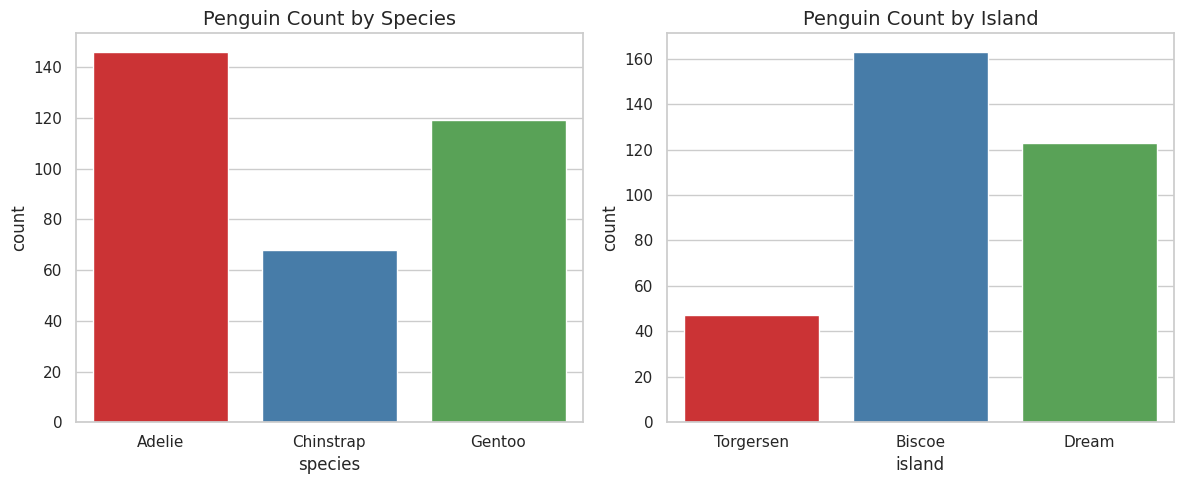

In [5]:
# TODO (8): In a 1x2 grid, plot a countplot of 'species' and a countplot of 'island'.
# Give each a clear title.

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.countplot(data=df, x='species', ax=axes[0], palette='Set1', hue='species', legend=False)
axes[0].set_title('Penguin Count by Species', fontsize=14)

sns.countplot(data=df, x='island', ax=axes[1], palette='Set1', hue='island', legend=False)
axes[1].set_title('Penguin Count by Island', fontsize=14)

plt.tight_layout()
plt.show()

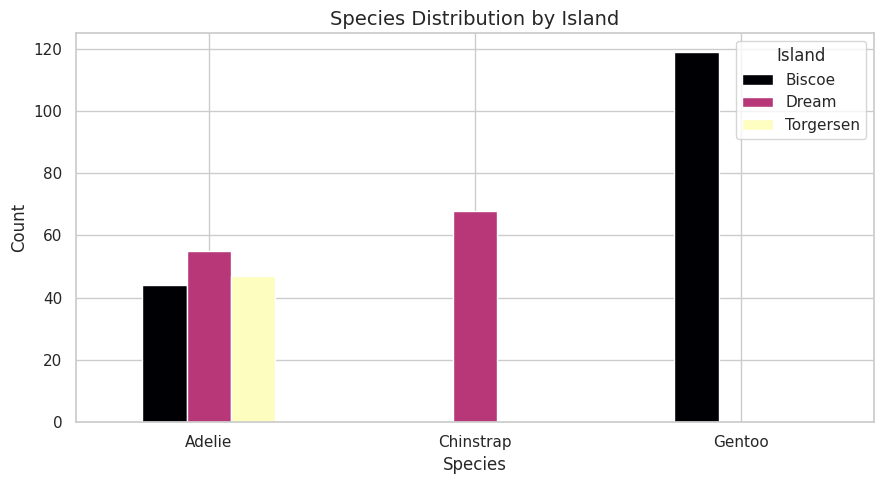

In [6]:
# TODO (7): Make a crosstab of species vs island (pd.crosstab) and plot it as a bar chart.
# Which islands does each species live on?

species_island_ct = pd.crosstab(df['species'], df['island'])

# Plotting with 'magma' colormap for a highly distinct look
species_island_ct.plot(kind='bar', figsize=(9, 5), colormap='magma')

plt.title('Species Distribution by Island', fontsize=14)
plt.ylabel('Count')
plt.xlabel('Species')
plt.xticks(rotation=0)
plt.legend(title='Island')

plt.tight_layout()
plt.show()

**✍️ Written Answer C:** Which species is the most common? Is any species found on only ONE island? (That's a huge clue for identification.)
*Your answer:*

Ans: The Adelie penguin is the most common species as ift is found on all islands. Yes, island location is a major clue: Gentoo penguins are found only on Biscoe Island, and Chinstrap penguins are found only on Dream Island. Adelie is the only species scattered across all three.

## Part D — Numerical EDA  *(20 marks)*
*Understand the four body measurements.*

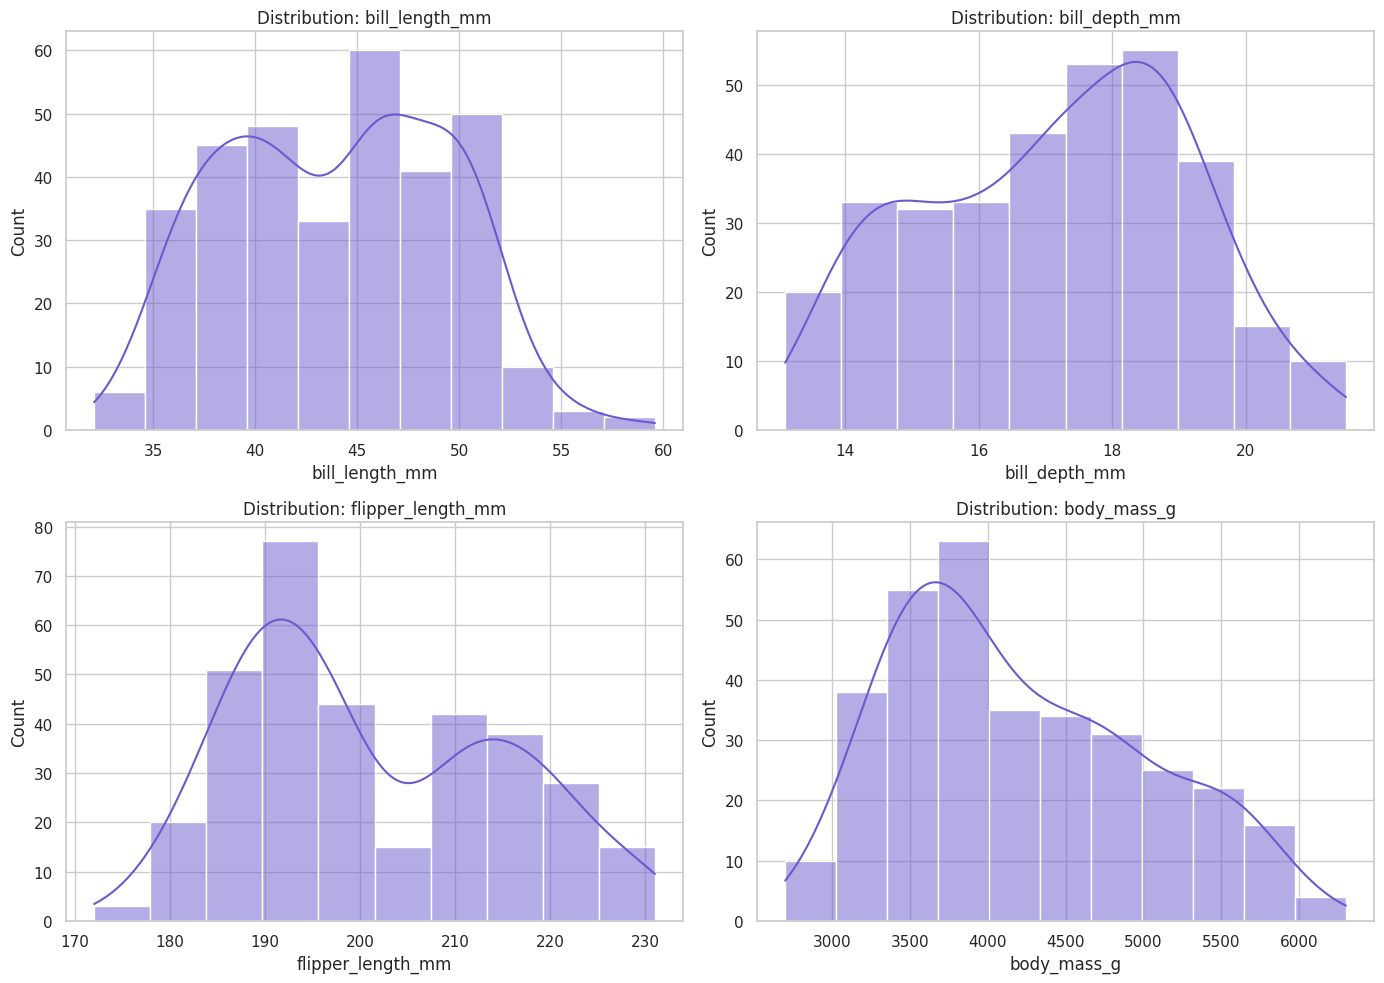

In [13]:
# TODO (10): For each of the 4 measurements
#   (bill_length_mm, bill_depth_mm, flipper_length_mm, body_mass_g),
# plot a histogram with kde=True. Arrange as a 2x2 grid.
# Look: are any distributions clearly split into groups (bumps)? That hints at species!

num_cols = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, col in zip(axes.flat, num_cols):
    sns.histplot(data=df, x=col, kde=True, ax=ax, color='slateblue')
    ax.set_title(f'Distribution: {col}', fontsize=12)

plt.tight_layout()
plt.show()

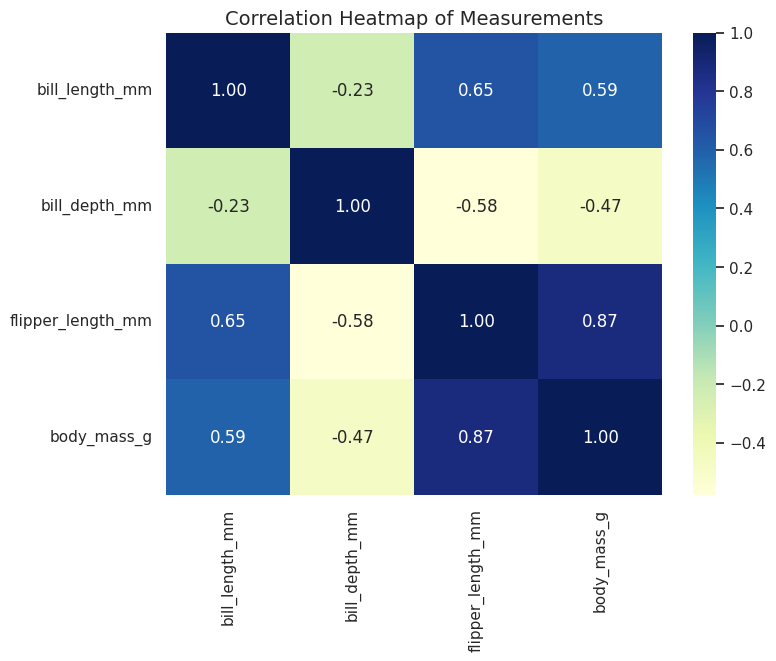

In [14]:
# TODO (10): Plot a correlation heatmap of the 4 numeric measurements (annot=True).
# Which two measurements are most strongly related?

plt.figure(figsize=(8, 6))

# 'YlGnBu' provides a clean, professional heat scale distinct from standard seaborn defaults
sns.heatmap(df[num_cols].corr(), annot=True, cmap='YlGnBu', fmt='.2f')
plt.title('Correlation Heatmap of Measurements', fontsize=14)

plt.show()

**✍️ Written Answer D:** Which two measurements have the strongest positive correlation, and does that make biological sense (think: bigger penguin → ?)
*Your answer:*

ANS: Flipper length and body mass have the strongest positive correlation (0.87). This makes perfect biological sense: a larger, heavier penguin requires longer and stronger flippers to propel its body mass effectively through the water.

## Part E — Species Fingerprints  *(25 marks)*  🎯 *the core of the assignment*
*This is where you crack the case: which measurements tell the species apart?*

In [15]:
# TODO (9): Compute the MEAN of each measurement grouped by species.
#   df.groupby('species')[num_cols].mean()
# This table is the heart of your field guide — study it.

species_averages = df.groupby('species')[num_cols].mean()
display(species_averages)

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
species,,,,
Adelie,38.823973,18.347260,190.102740,3706.164384
Chinstrap,48.833824,18.420588,195.823529,3733.088235
Gentoo,47.568067,14.996639,217.235294,5092.436975


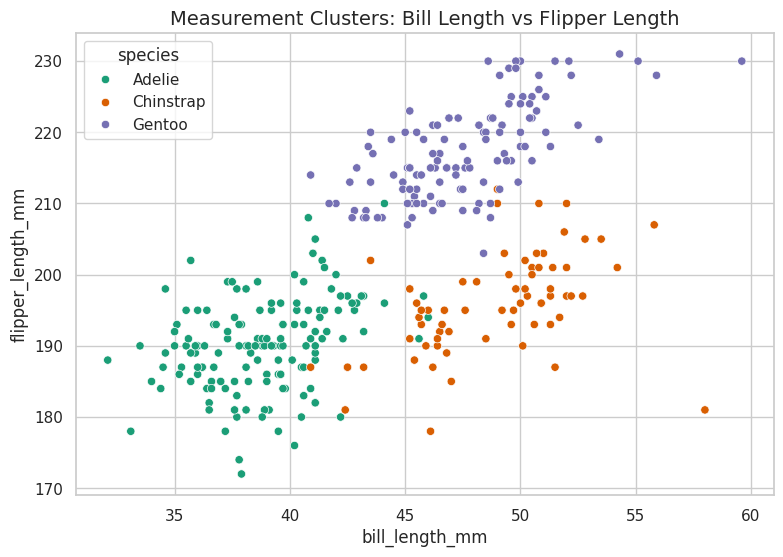

In [16]:
# TODO (8): Make a scatter plot of bill_length_mm (x) vs flipper_length_mm (y),
# coloured by species (hue='species'). Do the species form separate clusters?

plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x='bill_length_mm', y='flipper_length_mm', hue='species', palette='Dark2')

plt.title('Measurement Clusters: Bill Length vs Flipper Length', fontsize=14)
plt.show()

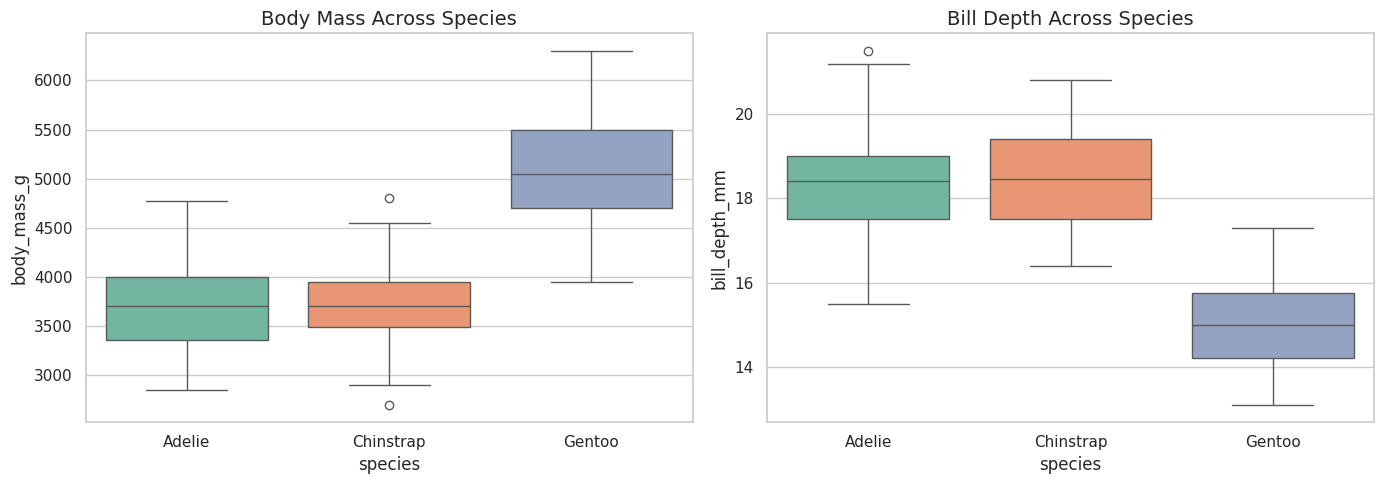

In [17]:
# TODO (8): Make boxplots of body_mass_g by species, and bill_depth_mm by species
# (1x2 grid). Which species is the clear outlier in size?

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=df, x='species', y='body_mass_g', ax=axes[0], palette='Set2', hue='species', legend=False)
axes[0].set_title('Body Mass Across Species', fontsize=14)

sns.boxplot(data=df, x='species', y='bill_depth_mm', ax=axes[1], palette='Set2', hue='species', legend=False)
axes[1].set_title('Bill Depth Across Species', fontsize=14)

plt.tight_layout()
plt.show()

**✍️ Written Answer E:** Describe each species in ONE sentence using measurements. For example: *"Gentoos are the ___ (heaviest/lightest), with the ___ flippers and a ___ bill."* Do this for all three species.

Ans:


**Adélie:** Adélies are the lightest birds with the shortest flippers, marked by a short but visibly deep bill.

**Chinstrap:** Chinstraps sit in the middle for weight and flipper length, distinguished clearly by having a bill that is both long and deep.

**Gentoo:** Gentoos are the heaviest penguins with the longest flippers, featuring a long but very shallow bill.

## Part F — Your Field Guide  *(15 marks)*
Write a short **field guide** (4–6 sentences) that a junior researcher could use to identify a penguin from measurements alone. Base every rule on your charts. A good guide gives simple decision rules, e.g. *"If flipper length > 210mm, it's almost certainly a Gentoo."*

**✍️ Your Field Guide:**

> To identify a penguin in the field using physical measurements, begin by checking its flipper length and overall mass. If flipper length exceeds 210 mm and body mass is well above 4,500 g, the specimen is a **Gentoo**, further confirmed by a slender bill depth near 15.0 mm. For smaller birds (under 4,200 g with flippers below 200 mm), inspect bill length to separate the remaining two species. If the bill is short (under 42 mm, average \~38.8 mm) with a thick, deep base (\~18.3 mm), it is an **Adélie**. If the bill is deep (\~18.4 mm) but significantly longer (over 45 mm, average \~48.8 mm), the penguin is a **Chinstrap**.





## 🌟 Bonus — Identify the Mystery Penguin  *(+10 marks)*
A researcher measured a penguin but forgot to record its species:

> **bill_length = 46 mm, bill_depth = 15 mm, flipper_length = 217 mm, body_mass = 5000 g**

Using your fingerprints from Part E, decide which species it is — and **justify with the data** (which measurements gave it away?).

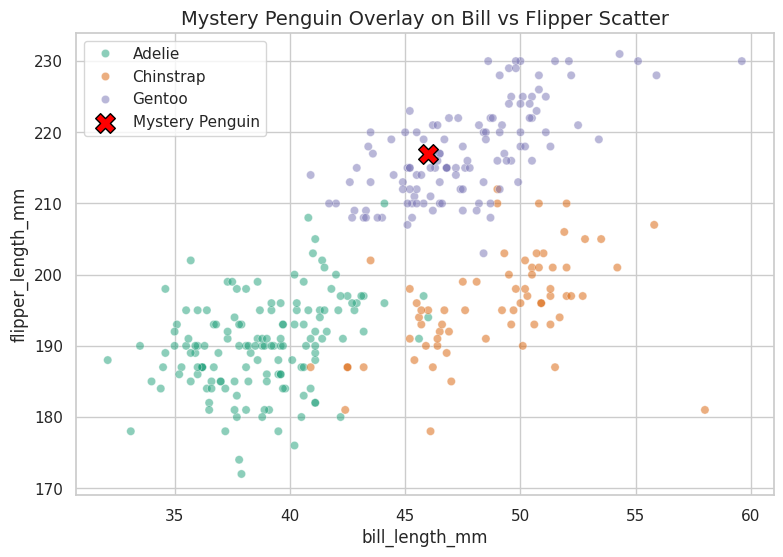

In [19]:
# TODO (bonus): Justify your answer with code — e.g. compare this penguin's numbers
# to the species means, or plot it on top of your scatter from Part E.

# Formatting the mystery penguin data
mystery_penguin = pd.DataFrame({
    'bill_length_mm': [46],
    'bill_depth_mm': [15],
    'flipper_length_mm': [217],
    'body_mass_g': [5000]
})

plt.figure(figsize=(9, 6))

# Plotting the original data with transparency
sns.scatterplot(data=df, x='bill_length_mm', y='flipper_length_mm', hue='species', palette='Dark2', alpha=0.5)

# Plotting the mystery bird with a bright red 'X' to stand out
plt.scatter(mystery_penguin['bill_length_mm'], mystery_penguin['flipper_length_mm'],
            color='red', marker='X', s=200, edgecolor='black', label='Mystery Penguin')

plt.title('Mystery Penguin Overlay on Bill vs Flipper Scatter', fontsize=14)
plt.legend()
plt.show()

**✍️ Bonus Answer:** This penguin is a **Gentoo**, because the mass (5000g) and flipper length (217mm) far exceed the natural upper limits of the other two species. Additionally, the bill depth is incredibly shallow (15mm), which is a definitive trait of the Gentoo species compared to the 18mm+ depth seen in Adélies and Chinstraps.

---
### ✅ Before you submit
- [ ] Every `# TODO` cell has working code
- [ ] Every ✍️ Written Answer is filled in
- [ ] You ran **Kernel → Restart & Run All** with no errors
- [ ] Charts have titles and are readable

*Good luck, field biologist!* 🐧